# Student CGPA Prediction – Regression Model Comparison

In [1]:
!pip install pandas numpy scikit-learn

In [2]:
import os

# Create dataset directories safely (also works when they already exist)
os.makedirs("datasets/raw", exist_ok=True)
os.makedirs("datasets/formatted", exist_ok=True)

print("Dataset directories are ready!")

Dataset directories are ready!


In [ ]:
!pwd

#Data Preprocessing & Cleaning

##Cleaning data

In [3]:
import pandas as pd

df = pd.read_csv("datasets/raw/studentData.csv")

# Convert 5 point GPA to percentage
df["class_12_percentage"] = round((
    df["class_12_percentage"] / 5
) * 100, 4)

df["class_10_percentage"] = round((
    df["class_10_percentage"] / 5
) * 100, 4)

# Convert 4 point CGPA to 10 point CGPA
df["previous_semester_cgpa"] = round((
    df["previous_semester_cgpa"] / 4
) * 10, 2)

df["next_semester_cgpa"] = round((
    df["next_semester_cgpa"] / 4
) * 10, 2)

df.to_csv("datasets/formatted/studentData.csv", index=False)

### Preprocessing

In [4]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Load formatted dataset
df = pd.read_csv("datasets/formatted/studentData.csv")

# Clean column names and categorical text
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Ensure numerical columns are numeric
numerical_features = [
    "class_12_percentage",
    "class_10_percentage",
    "previous_semester_cgpa"
]

for col in numerical_features + ["next_semester_cgpa"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows without target values
df = df.dropna(subset=["next_semester_cgpa"])

# Define feature groups
nominal_features = ["hometown"]

ordinal_features = [
    "family_income",
    "exam_preparation",
    "gaming_hours",
    "attendance_percentage"
]

# Define actual category order
ordinal_categories = [
    [
        "Low (Below 15,000)",
        "Lower middle (15,000-30,000)",
        "Upper middle (30,000-50,000)",
        "High (Above 50,000)"
    ],
    [
        "0-1 Hour",
        "2-3 Hours",
        "More than 3 Hours"
    ],
    [
        "0-1 Hour",
        "2-3 Hours",
        "More than 3 Hours"
    ],
    [
        "Below 40%",
        "40%-59%",
        "60%-79%",
        "80%-100%"
    ]
]

# Numerical preprocessing
numerical_transformer = SimpleImputer(strategy="median")

# Nominal preprocessing
nominal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Ordinal preprocessing
ordinal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_transformer, numerical_features),
        ("nominal", nominal_transformer, nominal_features),
        ("ordinal", ordinal_transformer, ordinal_features)
    ]
)

print("Preprocessing configuration completed!")


Preprocessing configuration completed!


###Train/Test Data Split

In [5]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["next_semester_cgpa"])
y = df["next_semester_cgpa"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 394
Testing records: 99


### Compare Regression Models

In [6]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor
)
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline

# Candidate regression algorithms.
# The same preprocessing and cross-validation folds are used for every model.
regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.001, max_iter=20000),
    "Elastic Net": ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000),
    "K-Neighbors Regressor": KNeighborsRegressor(
        n_neighbors=5,
        weights="distance"
    ),
    "Support Vector Regressor": SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1
    ),
    "Decision Tree Regressor": DecisionTreeRegressor(
        min_samples_leaf=2,
        random_state=42
    ),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=1
    ),
    "Extra Trees Regressor": ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=1
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        loss="huber",
        random_state=42
    ),
    "AdaBoost Regressor": AdaBoostRegressor(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42
    )
}

# Use identical shuffled folds for a fair comparison.
regression_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Keep preprocessing inside each pipeline to prevent data leakage.
def make_regression_pipeline(regressor):
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        # Scaling helps distance-based and regularized models.
        # with_mean=False also supports sparse one-hot encoded features.
        ("scaler", StandardScaler(with_mean=False)),
        ("regressor", regressor)
    ])

comparison_rows = []
regression_cv_details = {}

for model_name, regressor in regressors.items():
    candidate_pipeline = make_regression_pipeline(regressor)

    cv_result = cross_validate(
        candidate_pipeline,
        X_train,
        y_train,
        cv=regression_cv,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error"
        },
        n_jobs=-1,
        return_train_score=False
    )

    # Convert negative sklearn loss scores back to positive error values.
    fold_r2 = cv_result["test_r2"]
    fold_mae = -cv_result["test_mae"]
    fold_rmse = np.sqrt(-cv_result["test_mse"])

    regression_cv_details[model_name] = {
        "r2": fold_r2,
        "mae": fold_mae,
        "rmse": fold_rmse
    }

    comparison_rows.append({
        "Model": model_name,
        "Mean CV R2": fold_r2.mean(),
        "Std CV R2": fold_r2.std(),
        "Mean CV MAE": fold_mae.mean(),
        "Mean CV RMSE": fold_rmse.mean()
    })

# Rank models by the lowest mean cross-validation RMSE.
regression_results_df = (
    pd.DataFrame(comparison_rows)
    .sort_values(by="Mean CV RMSE", ascending=True)
    .reset_index(drop=True)
)

print("Regression Model Comparison (5-Fold Cross-Validation)")
print("------------------------------------------------------")
print(regression_results_df.round(4).to_string(index=False))

# Select the best model using training data cross-validation only.
best_regressor_name = regression_results_df.loc[0, "Model"]
print(f"\nBest model based on lowest CV RMSE: {best_regressor_name}")

# Refit the selected complete pipeline on the full training split.
best_regression_model = make_regression_pipeline(
    regressors[best_regressor_name]
)
best_regression_model.fit(X_train, y_train)

print("Best regression model trained successfully!")

Regression Model Comparison (5-Fold Cross-Validation)
------------------------------------------------------
                      Model  Mean CV R2  Std CV R2  Mean CV MAE  Mean CV RMSE
      Extra Trees Regressor      0.8435     0.0538       0.3358        0.5729
    Random Forest Regressor      0.8414     0.0541       0.3338        0.5754
Gradient Boosting Regressor      0.8368     0.0536       0.3400        0.5867
   Support Vector Regressor      0.8358     0.0373       0.3457        0.5906
           Lasso Regression      0.8333     0.0377       0.3731        0.5955
                Elastic Net      0.8332     0.0377       0.3733        0.5957
           Ridge Regression      0.8332     0.0372       0.3740        0.5957
          Linear Regression      0.8330     0.0380       0.3732        0.5961
    Decision Tree Regressor      0.7881     0.0783       0.3756        0.6561
         AdaBoost Regressor      0.7888     0.0622       0.4464        0.6645
      K-Neighbors Regressor      

### Performance Evaluation – Best Regression Model

In [7]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict the held-out test set only after model selection is complete.
y_pred = best_regression_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Best Model: {best_regressor_name}")
print("Test Set Evaluation")
print("-------------------")
print(f"MAE:  {mae:.4f} CGPA points")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f} CGPA points")
print(f"R2:   {r2:.4f}")

Best Model: Extra Trees Regressor
Test Set Evaluation
-------------------
MAE:  0.3454 CGPA points
MSE:  0.2457
RMSE: 0.4957 CGPA points
R2:   0.8947


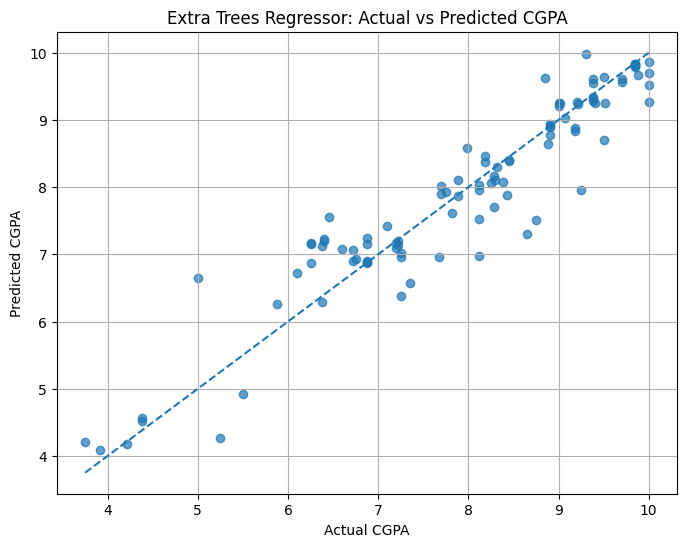

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual CGPA")
plt.ylabel("Predicted CGPA")
plt.title(f"{best_regressor_name}: Actual vs Predicted CGPA")
plt.grid(True)
plt.show()

### Cross-validation Results

In [9]:
# Display the cross-validation results used to select the best regressor.
print("Cross-validation summary (training split only)")
print("-----------------------------------------------")
print(regression_results_df.round(4).to_string(index=False))

best_cv = regression_cv_details[best_regressor_name]
print(f"\nSelected model: {best_regressor_name}")
print(f"Mean CV R2:   {best_cv['r2'].mean():.4f} ± {best_cv['r2'].std():.4f}")
print(f"Mean CV MAE:  {best_cv['mae'].mean():.4f}")
print(f"Mean CV RMSE: {best_cv['rmse'].mean():.4f}")

Cross-validation summary (training split only)
-----------------------------------------------
                      Model  Mean CV R2  Std CV R2  Mean CV MAE  Mean CV RMSE
      Extra Trees Regressor      0.8435     0.0538       0.3358        0.5729
    Random Forest Regressor      0.8414     0.0541       0.3338        0.5754
Gradient Boosting Regressor      0.8368     0.0536       0.3400        0.5867
   Support Vector Regressor      0.8358     0.0373       0.3457        0.5906
           Lasso Regression      0.8333     0.0377       0.3731        0.5955
                Elastic Net      0.8332     0.0377       0.3733        0.5957
           Ridge Regression      0.8332     0.0372       0.3740        0.5957
          Linear Regression      0.8330     0.0380       0.3732        0.5961
    Decision Tree Regressor      0.7881     0.0783       0.3756        0.6561
         AdaBoost Regressor      0.7888     0.0622       0.4464        0.6645
      K-Neighbors Regressor      0.7203     0.0

### Residual Analysis

`Residual = Actual - Predicted`

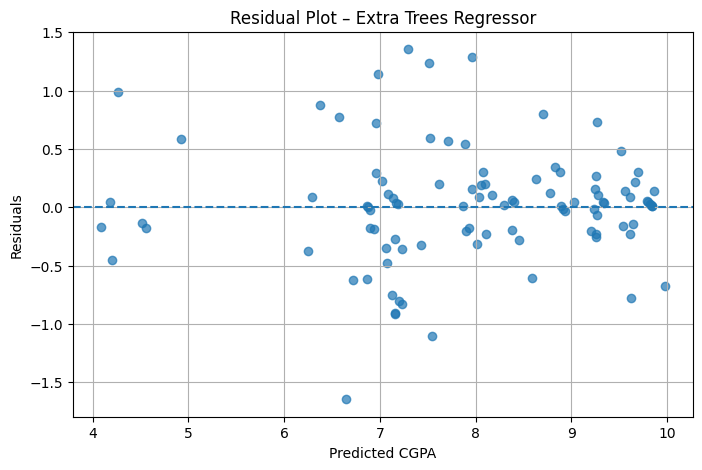

In [10]:
import matplotlib.pyplot as plt

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted CGPA")
plt.ylabel("Residuals")
plt.title(f"Residual Plot – {best_regressor_name}")
plt.grid(True)
plt.show()

In [11]:

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Same validation folds for both models
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model A: All features
model_all = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

scores_all = cross_val_score(
    model_all,
    X,
    y,
    cv=kf,
    scoring="r2"
)

# Model B: Previous CGPA only
model_previous = LinearRegression()

X_previous = df[["previous_semester_cgpa"]]

scores_previous = cross_val_score(
    model_previous,
    X_previous,
    y,
    cv=kf,
    scoring="r2"
)

print("MODEL A - ALL FEATURES")
print("Fold scores:", scores_all)
print("Mean R2:", scores_all.mean())

print("\nMODEL B - PREVIOUS CGPA ONLY")
print("Fold scores:", scores_previous)
print("Mean R2:", scores_previous.mean())

print("\nPerformance Difference:")
print("R2 improvement:", scores_all.mean() - scores_previous.mean())


MODEL A - ALL FEATURES
Fold scores: [0.90183652 0.76272779 0.8518811  0.89596081 0.88057682]
Mean R2: 0.8585966092111912

MODEL B - PREVIOUS CGPA ONLY
Fold scores: [0.90413006 0.76904424 0.8505516  0.90023676 0.87629455]
Mean R2: 0.8600514429612595

Performance Difference:
R2 improvement: -0.001454833750068274


### Save the Best Regression Model

In [12]:
import joblib

# Save the complete fitted pipeline, including preprocessing and the selected regressor.
joblib.dump(
    best_regression_model,
    "cgpa_prediction_model.pkl"
)

# Also save the comparison table so the model selection is documented.
regression_results_df.to_csv(
    "regression_model_comparison.csv",
    index=False
)

print(f"Saved best model: {best_regressor_name}")
print("Model file: cgpa_prediction_model.pkl")
print("Comparison file: regression_model_comparison.csv")

Saved best model: Extra Trees Regressor
Model file: cgpa_prediction_model.pkl
Comparison file: regression_model_comparison.csv


#Performance Prediction

###Preparing Dataset

In [13]:

import pandas as pd

# Load dataset
df = pd.read_csv("datasets/formatted/studentData.csv")

# Convert CGPA into performance categories
def classify_performance(cgpa):
    if cgpa >= 9.0:
        return "Excellent"
    elif cgpa >= 8.0:
        return "Very Good"
    elif cgpa >= 7.0:
        return "Good"
    elif cgpa >= 6.0:
        return "Average"
    else:
        return "Poor"

# Create performance column
df["performance"] = df["next_semester_cgpa"].apply(
    classify_performance
)

# Remove original CGPA target
df.drop(columns=["next_semester_cgpa"], inplace=True)

# Save new dataset
df.to_csv("datasets/formatted/studentPerformance.csv", index=False)

# Display results
print(df.head())
print("\nPerformance Distribution:")
print(df["performance"].value_counts())

print("\nDataset saved as studentPerformance.csv")


   class_12_percentage  class_10_percentage                 family_income  \
0                 83.4                 96.8            Low (Below 15,000)   
1                 98.4                100.0  Upper middle (30,000-50,000)   
2                100.0                 96.6  Lower middle (15,000-30,000)   
3                 80.0                 90.0           High (Above 50,000)   
4                 43.8                 63.4  Lower middle (15,000-30,000)   

  hometown   exam_preparation       gaming_hours attendance_percentage  \
0  Village  More than 3 Hours           0-1 Hour              80%-100%   
1     City           0-1 Hour           0-1 Hour              80%-100%   
2  Village           0-1 Hour  More than 3 Hours              80%-100%   
3     City  More than 3 Hours  More than 3 Hours              80%-100%   
4  Village           0-1 Hour          2-3 Hours              80%-100%   

   previous_semester_cgpa performance  
0                    8.05   Very Good  
1           

### Data Preprocessing

In [14]:

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Load performance dataset
df = pd.read_csv("datasets/formatted/studentPerformance.csv")

df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Feature groups
numerical_features = [
    "class_12_percentage",
    "class_10_percentage",
    "previous_semester_cgpa"
]

nominal_features = ["hometown"]

ordinal_features = [
    "family_income",
    "exam_preparation",
    "gaming_hours",
    "attendance_percentage"
]

# Ordinal categories
ordinal_categories = [
    [
        "Low (Below 15,000)",
        "Lower middle (15,000-30,000)",
        "Upper middle (30,000-50,000)",
        "High (Above 50,000)"
    ],
    [
        "0-1 Hour",
        "2-3 Hours",
        "More than 3 Hours"
    ],
    [
        "0-1 Hour",
        "2-3 Hours",
        "More than 3 Hours"
    ],
    [
        "Below 40%",
        "40%-59%",
        "60%-79%",
        "80%-100%"
    ]
]

# Preprocessing transformers
numerical_transformer = SimpleImputer(
    strategy="median"
)

nominal_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

ordinal_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

# Combined preprocessor
preprocessor = ColumnTransformer([
    ("numerical", numerical_transformer, numerical_features),
    ("nominal", nominal_transformer, nominal_features),
    ("ordinal", ordinal_transformer, ordinal_features)
])

print("Classification preprocessing completed!")


Classification preprocessing completed!


###Train/Test Data Split

In [15]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["performance"])
y = df["performance"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())


Training records: 394
Testing records: 99

Training distribution:
performance
Excellent    121
Very Good    106
Good          78
Poor          46
Average       43
Name: count, dtype: int64


###Train and compare ML algorithms

In [16]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import StratifiedKFold, cross_val_score

# Define classification algorithms
classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    )
}

# Stratified 5-fold cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = {}

for name, classifier in classifiers.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=skf,
        scoring="f1_macro"
    )

    results[name] = scores.mean()

    print(f"\n{name}")
    print("Fold scores:", scores)
    print("Mean F1:", scores.mean())

# Select the best model based on CV
best_model_name = max(results, key=results.get)

print("\nBest Model:", best_model_name)
print("Best CV Macro F1:", results[best_model_name])


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Logistic Regression
Fold scores: [0.63994314 0.60311688 0.62471363 0.62863317 0.62714908]
Mean F1: 0.6247111795786262

Decision Tree
Fold scores: [0.61628318 0.69067363 0.67959543 0.67146568 0.6564957 ]
Mean F1: 0.6629027233484288

Random Forest
Fold scores: [0.69526936 0.70704778 0.6664986  0.61730282 0.69888193]
Mean F1: 0.6770000988741236

Best Model: Random Forest
Best CV Macro F1: 0.6770000988741236


###Performance Evaluation

In [17]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Build best model pipeline
best_classifier = classifiers[best_model_name]

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", best_classifier)
])

# Train model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Evaluation
print("Performance Classification Evaluation")
print("--------------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(
    y_test, y_pred, average="macro"
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Performance Classification Evaluation
--------------------------------------
Accuracy: 0.7878787878787878
Macro F1: 0.7824500100668952

Classification Report:
              precision    recall  f1-score   support

     Average       0.64      0.82      0.72        11
   Excellent       0.90      0.93      0.92        30
        Good       0.62      0.65      0.63        20
        Poor       0.92      0.92      0.92        12
   Very Good       0.81      0.65      0.72        26

    accuracy                           0.79        99
   macro avg       0.78      0.79      0.78        99
weighted avg       0.79      0.79      0.79        99



###Confusion Matrix

<Figure size 900x700 with 0 Axes>

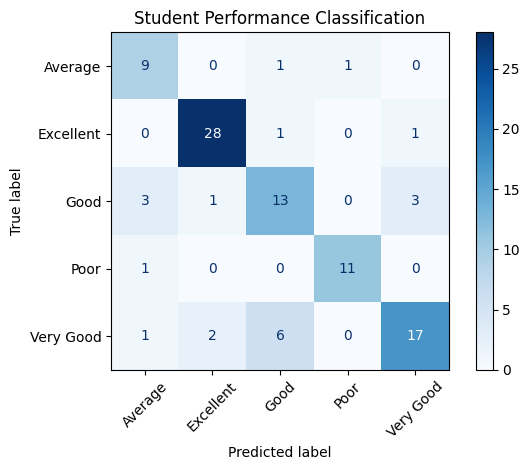

In [18]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Student Performance Classification")
plt.tight_layout()
plt.show()


#Save the model

In [19]:

import joblib

joblib.dump(
    model,
    "student_performance_model.pkl"
)

print("Performance model saved successfully!")


Performance model saved successfully!


# Backlog Prediction Model



In [22]:
from pathlib import Path
import pandas as pd

backlog_dataset_path = "datasets/formatted/backlog_prediction_dataset.csv"
backlog_df = pd.read_csv(backlog_dataset_path)
backlog_df.columns = backlog_df.columns.str.strip()

backlog_features = [
    "previous_semester_cgpa",
    "attendance_percentage",
    "previous_backlogs",
    "study_time_hours_per_day",
]
backlog_target = "backlog_status"
required_backlog_columns = backlog_features + [backlog_target]
missing_backlog_columns = [
    column for column in required_backlog_columns
    if column not in backlog_df.columns
]
if missing_backlog_columns:
    raise ValueError(
        f"The backlog dataset is missing required columns: {missing_backlog_columns}"
    )

# Keep only the agreed model inputs and target, in a predictable order.
backlog_df = backlog_df[required_backlog_columns].copy()
for column in backlog_features:
    backlog_df[column] = pd.to_numeric(backlog_df[column], errors="coerce")
backlog_df[backlog_target] = backlog_df[backlog_target].astype("string").str.strip()

# Remove records without a known target; feature gaps are imputed inside the pipeline.
backlog_df = backlog_df.dropna(subset=[backlog_target]).reset_index(drop=True)
valid_backlog_labels = {"Backlog", "No Backlog"}
found_backlog_labels = set(backlog_df[backlog_target].dropna().unique())
if not found_backlog_labels.issubset(valid_backlog_labels):
    raise ValueError(
        f"Unexpected target labels: {found_backlog_labels - valid_backlog_labels}. "
        "Expected only 'Backlog' and 'No Backlog'."
    )

# Basic range checks help catch incorrect CSV formatting.
if not backlog_df["previous_semester_cgpa"].dropna().between(0, 10).all():
    raise ValueError("previous_semester_cgpa must be between 0 and 10.")
if not backlog_df["attendance_percentage"].dropna().between(0, 100).all():
    raise ValueError("attendance_percentage must be between 0 and 100.")
if (backlog_df["previous_backlogs"].dropna() < 0).any():
    raise ValueError("previous_backlogs cannot be negative.")
if (backlog_df["study_time_hours_per_day"].dropna() < 0).any():
    raise ValueError("study_time_hours_per_day cannot be negative.")

print("Dataset path:", backlog_dataset_path)
print("Dataset shape:", backlog_df.shape)
print("\nTarget distribution:")
print(backlog_df[backlog_target].value_counts())
print("\nTarget percentages:")
print((backlog_df[backlog_target].value_counts(normalize=True) * 100).round(2))
print("\nPreview:")
display(backlog_df.head())


Dataset path: datasets/formatted/backlog_prediction_dataset.csv
Dataset shape: (493, 5)

Target distribution:
backlog_status
No Backlog    355
Backlog       138
Name: count, dtype: Int64

Target percentages:
backlog_status
No Backlog    72.01
Backlog       27.99
Name: proportion, dtype: Float64

Preview:


,previous_semester_cgpa,attendance_percentage,previous_backlogs,study_time_hours_per_day,backlog_status
0,8.05,90,0,4.0,No Backlog
1,8.67,90,1,0.5,No Backlog
2,10.00,90,0,0.5,No Backlog
3,9.50,90,0,4.0,No Backlog
4,9.85,90,0,0.5,No Backlog


### Train/test split

Use a stratified split so the Backlog / No Backlog proportions are maintained in both sets. The test set is held aside for the final evaluation.


In [23]:
from sklearn.model_selection import train_test_split

X_backlog = backlog_df[backlog_features]
y_backlog = backlog_df[backlog_target]

X_backlog_train, X_backlog_test, y_backlog_train, y_backlog_test = train_test_split(
    X_backlog,
    y_backlog,
    test_size=0.20,
    random_state=42,
    stratify=y_backlog,
)

print("Training records:", len(X_backlog_train))
print("Testing records:", len(X_backlog_test))
print("\nTraining target distribution:")
print(y_backlog_train.value_counts())
print("\nTesting target distribution:")
print(y_backlog_test.value_counts())


Training records: 394
Testing records: 99

Training target distribution:
backlog_status
No Backlog    284
Backlog       110
Name: count, dtype: Int64

Testing target distribution:
backlog_status
No Backlog    71
Backlog       28
Name: count, dtype: Int64


### Compare classification algorithms


In [24]:
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score, precision_score, recall_score

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
)

# All inputs are numeric. Imputation and scaling are fitted separately inside
# each CV fold, preventing preprocessing leakage.
def make_backlog_pipeline(classifier):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", classifier),
    ])

backlog_classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42,
    ),
    "K-Neighbors Classifier": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
    ),
    "Support Vector Machine": SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        probability=True,
        random_state=42,
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=8,
        class_weight="balanced",
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=1,
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42,
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=150,
        learning_rate=0.05,
        random_state=42,
    ),
}

# Explicitly define Backlog as the positive class for all selection metrics.
backlog_f1_scorer = make_scorer(
    f1_score, pos_label="Backlog", zero_division=0
)
backlog_precision_scorer = make_scorer(
    precision_score, pos_label="Backlog", zero_division=0
)
backlog_recall_scorer = make_scorer(
    recall_score, pos_label="Backlog", zero_division=0
)

backlog_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

backlog_scoring = {
    "accuracy": "accuracy",
    "precision_backlog": backlog_precision_scorer,
    "recall_backlog": backlog_recall_scorer,
    "f1_backlog": backlog_f1_scorer,
}

backlog_comparison_rows = []
backlog_cv_details = {}

for classifier_name, classifier in backlog_classifiers.items():
    candidate_pipeline = make_backlog_pipeline(classifier)

    cv_scores = cross_validate(
        candidate_pipeline,
        X_backlog_train,
        y_backlog_train,
        cv=backlog_cv,
        scoring=backlog_scoring,
        n_jobs=-1,
        return_train_score=False,
    )

    backlog_cv_details[classifier_name] = cv_scores
    backlog_comparison_rows.append({
        "Model": classifier_name,
        "Mean CV Accuracy": cv_scores["test_accuracy"].mean(),
        "Mean CV Precision (Backlog)": cv_scores["test_precision_backlog"].mean(),
        "Mean CV Recall (Backlog)": cv_scores["test_recall_backlog"].mean(),
        "Mean CV F1 (Backlog)": cv_scores["test_f1_backlog"].mean(),
        "Std CV F1 (Backlog)": cv_scores["test_f1_backlog"].std(),
    })

backlog_results_df = (
    pd.DataFrame(backlog_comparison_rows)
    .sort_values(
        by=["Mean CV F1 (Backlog)", "Mean CV Recall (Backlog)"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

print("Backlog Classification Model Comparison (5-Fold CV)")
print("----------------------------------------------------")
print(backlog_results_df.round(4).to_string(index=False))

# Select using training CV only. The held-out test set is not used here.
best_backlog_classifier_name = backlog_results_df.loc[0, "Model"]
best_backlog_classifier = backlog_classifiers[best_backlog_classifier_name]

backlog_model = make_backlog_pipeline(best_backlog_classifier)
backlog_model.fit(X_backlog_train, y_backlog_train)

print(f"\nSelected model: {best_backlog_classifier_name}")
print("Selection metric: highest mean CV F1-score for the Backlog class")
print("Best mean CV Backlog F1:", round(
    backlog_results_df.loc[0, "Mean CV F1 (Backlog)"], 4
))
print("Best mean CV Backlog recall:", round(
    backlog_results_df.loc[0, "Mean CV Recall (Backlog)"], 4
))


Backlog Classification Model Comparison (5-Fold CV)
----------------------------------------------------
                 Model  Mean CV Accuracy  Mean CV Precision (Backlog)  Mean CV Recall (Backlog)  Mean CV F1 (Backlog)  Std CV F1 (Backlog)
K-Neighbors Classifier            0.9899                       0.9818                    0.9818                0.9818               0.0223
              AdaBoost            0.9771                       0.9409                    0.9818                0.9606               0.0350
     Gradient Boosting            0.9772                       0.9576                    0.9636                0.9600               0.0319
         Random Forest            0.9746                       0.9409                    0.9727                0.9559               0.0307
         Decision Tree            0.9746                       0.9481                    0.9636                0.9553               0.0235
   Logistic Regression            0.9441                     

### Evaluate the selected backlog model



In [25]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

backlog_y_pred = backlog_model.predict(X_backlog_test)

backlog_test_accuracy = accuracy_score(y_backlog_test, backlog_y_pred)
backlog_test_balanced_accuracy = balanced_accuracy_score(
    y_backlog_test, backlog_y_pred
)
backlog_test_precision = precision_score(
    y_backlog_test, backlog_y_pred,
    pos_label="Backlog", zero_division=0
)
backlog_test_recall = recall_score(
    y_backlog_test, backlog_y_pred,
    pos_label="Backlog", zero_division=0
)
backlog_test_f1 = f1_score(
    y_backlog_test, backlog_y_pred,
    pos_label="Backlog", zero_division=0
)

print("Selected model:", best_backlog_classifier_name)
print("\nHeld-out test results")
print("---------------------")
print(f"Accuracy:          {backlog_test_accuracy:.4f}")
print(f"Balanced Accuracy: {backlog_test_balanced_accuracy:.4f}")
print(f"Backlog Precision: {backlog_test_precision:.4f}")
print(f"Backlog Recall:    {backlog_test_recall:.4f}")
print(f"Backlog F1-score:  {backlog_test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_backlog_test,
    backlog_y_pred,
    labels=["Backlog", "No Backlog"],
    zero_division=0,
))


Selected model: K-Neighbors Classifier

Held-out test results
---------------------
Accuracy:          1.0000
Balanced Accuracy: 1.0000
Backlog Precision: 1.0000
Backlog Recall:    1.0000
Backlog F1-score:  1.0000

Classification Report:
              precision    recall  f1-score   support

     Backlog       1.00      1.00      1.00        28
  No Backlog       1.00      1.00      1.00        71

    accuracy                           1.00        99
   macro avg       1.00      1.00      1.00        99
weighted avg       1.00      1.00      1.00        99



### Confusion matrix

Rows show actual classes and columns show predicted classes. A false negative is an actual Backlog record predicted as No Backlog.


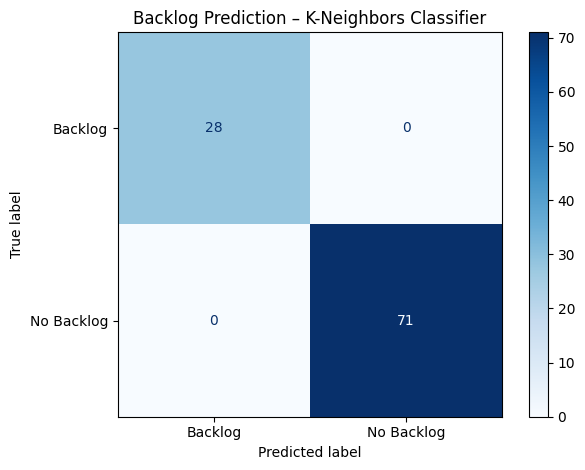

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_backlog_test,
    backlog_y_pred,
    labels=["Backlog", "No Backlog"],
    display_labels=["Backlog", "No Backlog"],
    cmap="Blues",
    values_format="d",
)
plt.title(f"Backlog Prediction – {best_backlog_classifier_name}")
plt.tight_layout()
plt.show()


### Save the best backlog model

The saved file contains the full fitted pipeline, including imputation, scaling, and the selected classifier. The cross-validation comparison is saved separately for documentation.


In [27]:
import joblib

joblib.dump(
    backlog_model,
    "backlog_prediction_model.pkl",
)

backlog_results_df.to_csv(
    "backlog_model_comparison.csv",
    index=False,
)

print("Saved best backlog model:", best_backlog_classifier_name)
print("Model file: backlog_prediction_model.pkl")
print("Comparison file: backlog_model_comparison.csv")


Saved best backlog model: K-Neighbors Classifier
Model file: backlog_prediction_model.pkl
Comparison file: backlog_model_comparison.csv


### Example: predict backlog risk for a new student


In [31]:
# Example input values (replace these with the student's actual data).
new_student_backlog_data = pd.DataFrame([{
    "previous_semester_cgpa": 5.8,
    "attendance_percentage": 25,
    "previous_backlogs": 1,
    "study_time_hours_per_day": 1.0,
}])

predicted_backlog_status = backlog_model.predict(
    new_student_backlog_data
)[0]

print("Predicted status:", predicted_backlog_status)

# Display the model-estimated Backlog probability when supported.
if hasattr(backlog_model, "predict_proba"):
    class_names = list(backlog_model.named_steps["classifier"].classes_)
    backlog_class_index = class_names.index("Backlog")
    estimated_backlog_probability = backlog_model.predict_proba(
        new_student_backlog_data
    )[0, backlog_class_index]
    print(f"Estimated Backlog probability: {estimated_backlog_probability:.2%}")


Predicted status: Backlog
Estimated Backlog probability: 100.00%
